# LAB 7 - K-Means Clustering

**Student:** Yash Rajput  &nbsp;|&nbsp;  **Registration No:** 2427010652

Perform clustering with **K-Means** and determine the optimal number of clusters using the
**Elbow Method (WCSS)** and the **Silhouette Score**.

## 1. Import libraries, load data and view basic statistics

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("cluster_data.csv")

print("Dataset Info:")
print(df.info())
print("\nMissing Values:\n", df.isnull().sum())
df.describe()

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Feature 1  500 non-null    float64
 1   Feature 2  500 non-null    float64
dtypes: float64(2)
memory usage: 7.9 KB
None

Missing Values:
 Feature 1    0
Feature 2    0
dtype: int64


,Feature 1,Feature 2
count,500.000000,500.000000
mean,-1.565075,1.426539
std,4.858052,6.559466
min,-9.377942,-9.788765
25%,-6.137629,-5.828746
50%,-2.438134,1.844226
75%,3.788400,8.234310
max,8.334536,13.637564


## 2. Visualize data distribution and correlation

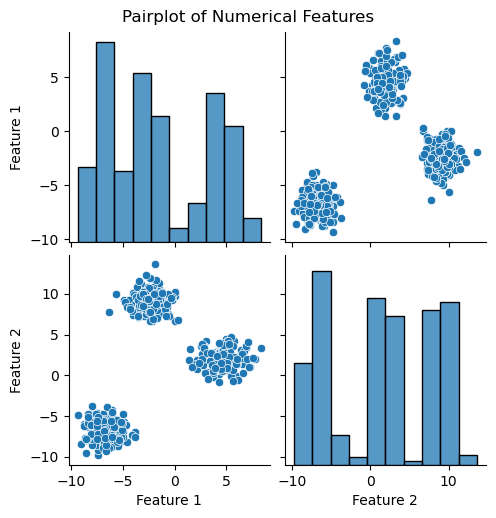

In [2]:
numerical_df = df.select_dtypes(include="number").dropna()

sns.pairplot(numerical_df)
plt.suptitle("Pairplot of Numerical Features", y=1.02)
plt.show()

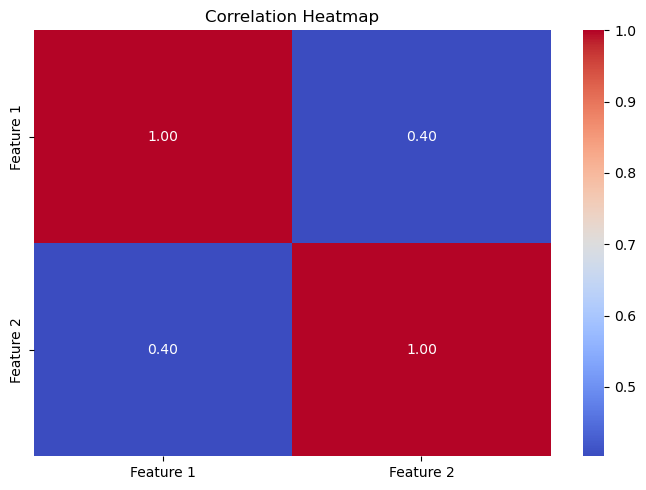

In [3]:
plt.figure(figsize=(7, 5))
sns.heatmap(numerical_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

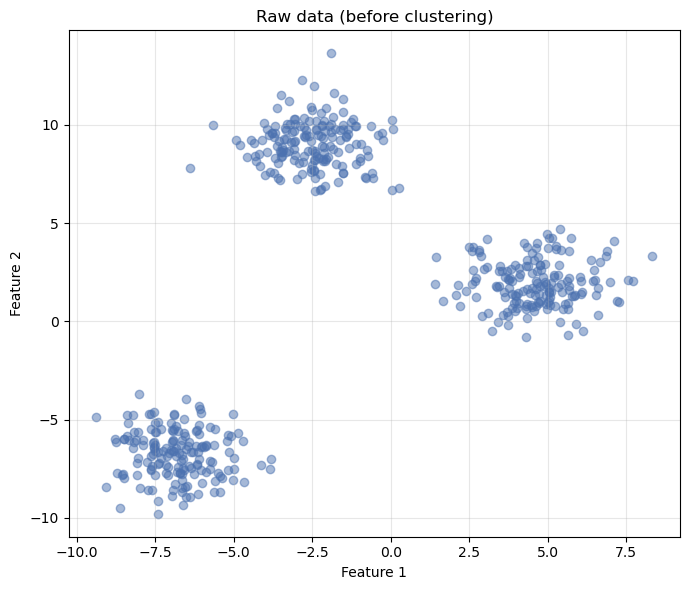

In [4]:
plt.figure(figsize=(7, 6))
plt.scatter(df["Feature 1"], df["Feature 2"], alpha=0.5, color="#4C72B0")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Raw data (before clustering)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Scale the data for K-Means

In [5]:
X = df.select_dtypes(include="number").dropna()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Scaled shape:", X_scaled.shape)

Scaled shape: (500, 2)


## 4. Elbow Method - find optimal k using WCSS

WCSS (Within-Cluster Sum of Squares) drops sharply and then flattens; the "elbow" marks the
optimal number of clusters.

C:\Users\Dell\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Dell\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\Dell\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Dell\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^

C:\Users\Dell\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Dell\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Dell\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


C:\Users\Dell\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Dell\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Dell\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


C:\Users\Dell\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Dell\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


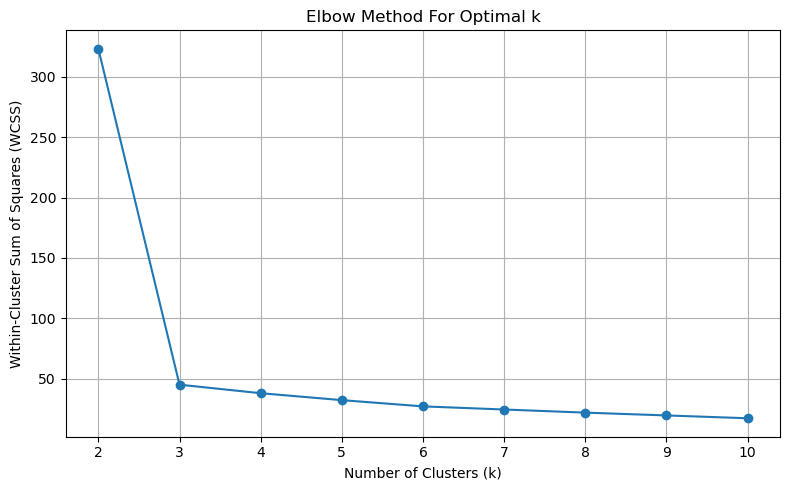

In [6]:
wcss = []
k_range = range(2, 11)
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_range, wcss, marker="o")
plt.title("Elbow Method For Optimal k")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Within-Cluster Sum of Squares (WCSS)")
plt.grid(True)
plt.tight_layout()
plt.show()

## 5. Silhouette Score - verify optimal k

The silhouette score (range -1 to 1) measures how well separated the clusters are. The highest
value indicates the best k.

C:\Users\Dell\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Dell\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


C:\Users\Dell\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Dell\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Dell\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


C:\Users\Dell\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Dell\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Dell\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


C:\Users\Dell\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


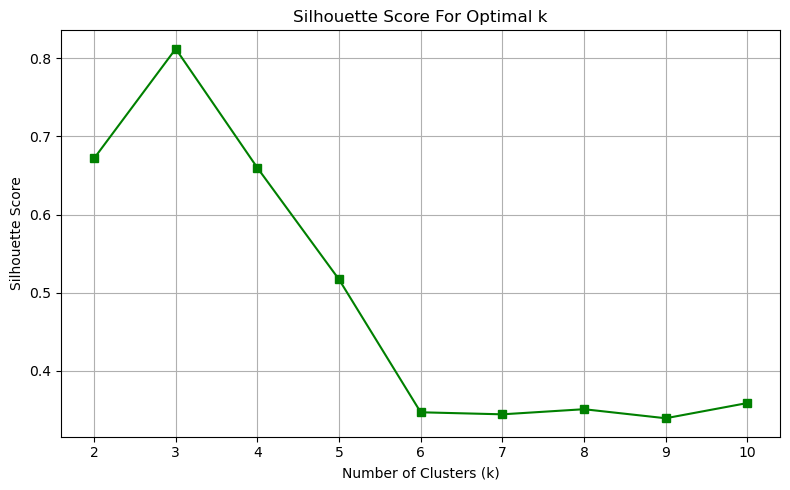

Silhouette scores: [np.float64(0.672), np.float64(0.812), np.float64(0.66), np.float64(0.517), np.float64(0.347), np.float64(0.344), np.float64(0.351), np.float64(0.339), np.float64(0.359)]
Best k by silhouette score: 3


In [7]:
silhouette_scores = []
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

plt.figure(figsize=(8, 5))
plt.plot(k_range, silhouette_scores, marker="s", color="green")
plt.title("Silhouette Score For Optimal k")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.tight_layout()
plt.show()

best_k = k_range[int(np.argmax(silhouette_scores))]
print("Silhouette scores:", [round(s, 3) for s in silhouette_scores])
print("Best k by silhouette score:", best_k)

## 6. Final K-Means clustering with the optimal k

In [8]:
optimal_k = int(best_k)
final_kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df["Cluster"] = final_kmeans.fit_predict(X_scaled)

print("Optimal number of clusters used:", optimal_k)
df.head()

Optimal number of clusters used: 3


C:\Users\Dell\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


,Feature 1,Feature 2,Cluster
0,-5.500499,-7.723921,1
1,1.403615,1.908016,0
2,7.267642,1.003212,0
3,-2.979727,7.258068,2
4,6.081336,1.483479,0


### 6.1 Visualize the final clusters

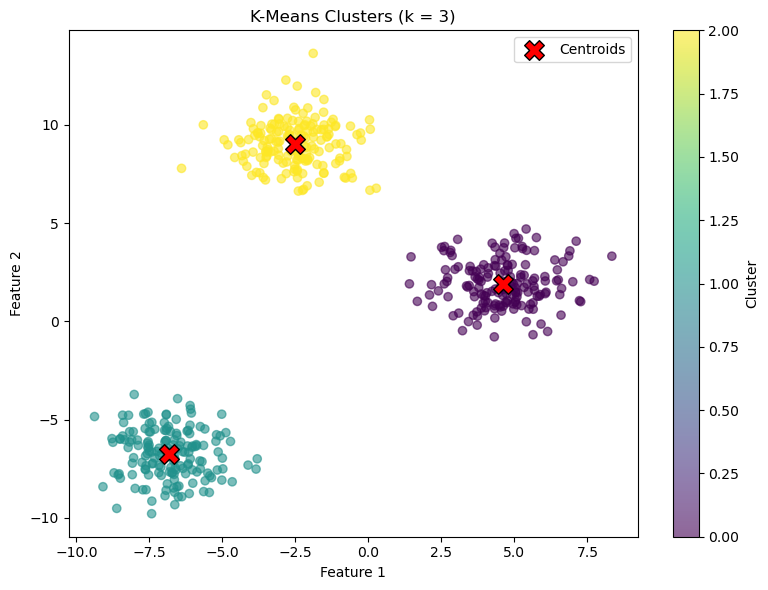

In [9]:
centers = scaler.inverse_transform(final_kmeans.cluster_centers_)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(df["Feature 1"], df["Feature 2"], c=df["Cluster"],
                      cmap="viridis", alpha=0.6)
plt.scatter(centers[:, 0], centers[:, 1], c="red", marker="X", s=200,
            edgecolor="black", label="Centroids")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title(f"K-Means Clusters (k = {optimal_k})")
plt.legend()
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

In [10]:
print("Number of points in each cluster:")
print(df["Cluster"].value_counts().sort_index())

Number of points in each cluster:
Cluster
0    167
1    166
2    167
Name: count, dtype: int64
